# Sub-Pixel Fourier Wafer Registration

Translation registration to 1/100 pixel for wafer-inspection and overlay-metrology images, written with NumPy and SciPy only:

* **phase correlation** finds the integer-pixel peak;
* **matrix-multiply DFT upsampling** (Guizar-Sicairos et al., 2008) refines it on a 1.5 × 1.5 px window at 0.01 px spacing, without a zero-padded FFT;
* **Fourier phase ramps** create exact sub-pixel test shifts with no interpolation blur;
* four **synthetic wafer topologies** (logic, DRAM array, overlay reticle, power/MEMS) with optical PSF blur and sensor noise.

Every number below is produced by this notebook from a fixed random seed. The library lives in `src/subpixel_registration.py`.

## 0 · Setup

In [ ]:
import io, json, os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

RESULTS = Path("results")
FIG = RESULTS / "figures"

SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
mpl.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.grid": True, "axes.axisbelow": True,
    "grid.color": "#e1e0d9", "grid.linewidth": 0.8, "grid.linestyle": "-",
    "axes.spines.top": False, "axes.spines.right": False,
    "text.color": INK, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "lines.linewidth": 2, "legend.frameon": False,
    "axes.prop_cycle": mpl.cycler(color=SERIES), "figure.dpi": 110, "savefig.dpi": 160,
})

import sys, time
sys.path.insert(0, "src")
from subpixel_registration import (register_subpixel_dft, apply_subpixel_shift_fourier, add_noise_snr,
                                   WAFERS, generate_wafer_logic)
UPSAMPLE = 100
rng = np.random.default_rng(42)

## 1 · Method

For reference image $f$ and shifted target $g(x) = f(x - \Delta)$, the normalised cross-power spectrum keeps only phase:

$$R(u,v) = \frac{G(u,v)\,F^*(u,v)}{\lvert G(u,v)\,F^*(u,v)\rvert} = e^{-i2\pi\left(\frac{u\Delta_y}{N} + \frac{v\Delta_x}{M}\right)}$$

Its inverse FFT is a sharp peak at $(\Delta_y, \Delta_x)$, which gives the integer-pixel estimate. To refine it to $1/\kappa$ px, the inverse DFT of $R$ is
evaluated only on a $1.5\kappa \times 1.5\kappa$ grid around that peak, as two matrix products:

$$r_\kappa = K_{\text{row}}\, R\, K_{\text{col}}, \qquad K_{\text{row}}[p, u] = e^{\,i\frac{2\pi}{N\kappa}(p - p_0)\,u}$$

This costs $O(\kappa N^2)$, against $O(\kappa^2 N^2 \log \kappa N)$ for zero-padding the whole spectrum by $\kappa$.
Test targets are shifted by multiplying the spectrum by the same linear phase ramp, so no interpolation blur enters the benchmark.

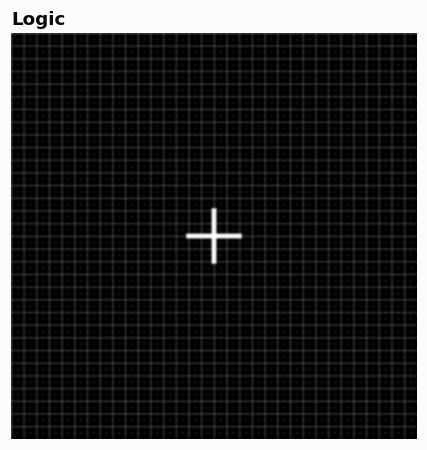

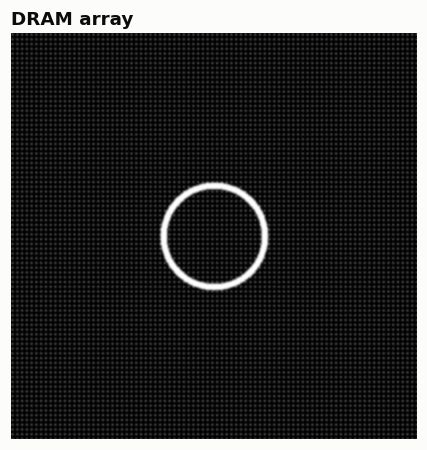

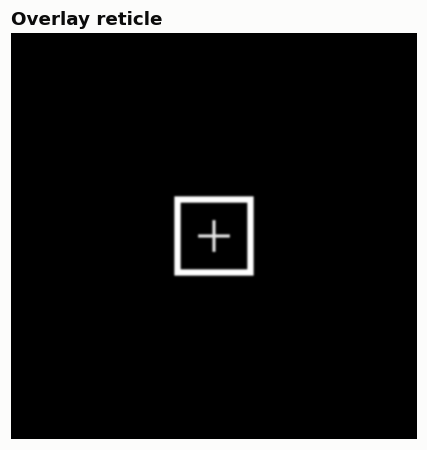

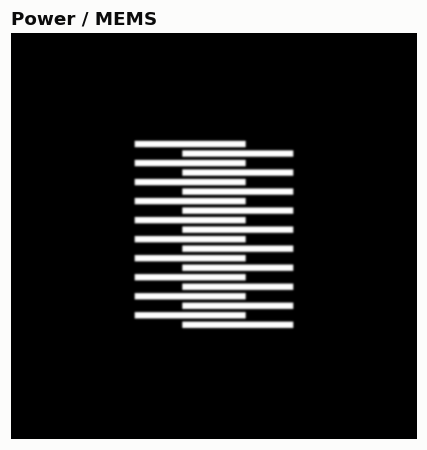

In [1]:
for name, gen in WAFERS.items():
    img = gen()
    fig, ax = plt.subplots(figsize=(4.2, 4.2))
    ax.imshow(img, cmap="gray"); ax.set_title(name); ax.axis("off")
    plt.tight_layout(); fig.savefig(FIG / f"wafer_{name.split()[0].lower().replace('/', '')}.png", dpi=120); plt.show()

## 2 · One registration, step by step (logic wafer, 30 dB SNR)

ground truth  (dy, dx) = (+3.4270, -5.1840) px
estimated     (dy, dx) = (+3.4300, -5.2000) px
vector error            = 0.0163 px


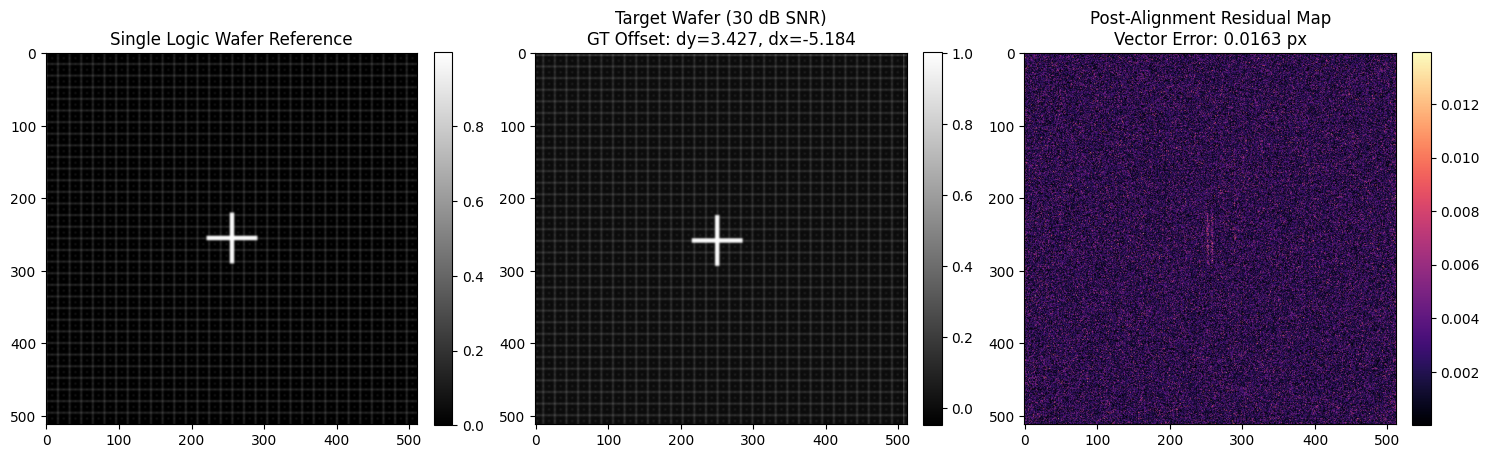

In [2]:
gt = (3.427, -5.184)
ref = generate_wafer_logic()
tgt = add_noise_snr(apply_subpixel_shift_fourier(ref, *gt), 30, rng)
res = register_subpixel_dft(ref, tgt, UPSAMPLE)
err = np.hypot(res.shift_y - gt[0], res.shift_x - gt[1])
print(f"ground truth  (dy, dx) = ({gt[0]:+.4f}, {gt[1]:+.4f}) px")
print(f"estimated     (dy, dx) = ({res.shift_y:+.4f}, {res.shift_x:+.4f}) px")
print(f"vector error            = {err:.4f} px")

aligned = apply_subpixel_shift_fourier(tgt, -res.shift_y, -res.shift_x)
residual = np.abs(ref - aligned)

with plt.style.context("default"):                     # same look as the original notebook figure
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
    im0 = axes[0].imshow(ref, cmap="gray")
    axes[0].set_title("Single Logic Wafer Reference")
    plt.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)
    im1 = axes[1].imshow(tgt, cmap="gray")
    axes[1].set_title(f"Target Wafer (30 dB SNR)\nGT Offset: dy={gt[0]:.3f}, dx={gt[1]:.3f}")
    plt.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)
    im2 = axes[2].imshow(residual, cmap="magma")
    axes[2].set_title(f"Post-Alignment Residual Map\nVector Error: {err:.4f} px")
    plt.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)
    plt.tight_layout(); fig.savefig(FIG / "single_registration_logic_30db.png", dpi=120); plt.show()

## 3 · Cross-check against scikit-image

`skimage.registration.phase_cross_correlation` implements the same published algorithm, so the two should agree to floating-point precision.
scikit-image is only needed for this check, not by the library.

In [3]:
from skimage.registration import phase_cross_correlation
diffs = []
for _ in range(50):
    g = rng.uniform(-8, 8, 2)
    t = add_noise_snr(apply_subpixel_shift_fourier(ref, *g), 30, rng).astype(np.float64)
    ours = register_subpixel_dft(ref, t, UPSAMPLE)
    theirs, _, _ = phase_cross_correlation(t, ref.astype(np.float64), upsample_factor=UPSAMPLE, normalization="phase")
    diffs.append(max(abs(ours.shift_y - theirs[0]), abs(ours.shift_x - theirs[1])))
print(f"largest difference from scikit-image over 50 random shifts: {max(diffs):.1e} px")

largest difference from scikit-image over 50 random shifts: 0.0e+00 px


## 4 · Accuracy across wafer types (25 dB SNR, 50 random shifts each)

In [4]:
def trial(gen_img, snr_db):
    g = rng.uniform(-8, 8, 2)
    t = add_noise_snr(apply_subpixel_shift_fourier(gen_img, *g), snr_db, rng)
    r = register_subpixel_dft(gen_img, t, UPSAMPLE)
    return np.hypot(r.shift_y - g[0], r.shift_x - g[1])

refs = {name: gen() for name, gen in WAFERS.items()}
by_wafer = pd.DataFrame([{"wafer": n, "vector error (px)": trial(img, 25)} for n, img in refs.items() for _ in range(50)])
wafer_table = by_wafer.groupby("wafer", sort=False)["vector error (px)"].agg(["mean", "std", "median", "max"]).round(4)
wafer_table.to_csv(RESULTS / "metrics/accuracy_by_wafer_25db.csv")
wafer_table

,mean,std,median,max
wafer,,,,
Logic,0.0263,0.0185,0.0238,0.1071
DRAM array,0.0151,0.0069,0.0153,0.0320
Overlay reticle,0.0347,0.0185,0.0305,0.0906
Power / MEMS,0.0856,0.0385,0.0797,0.1887


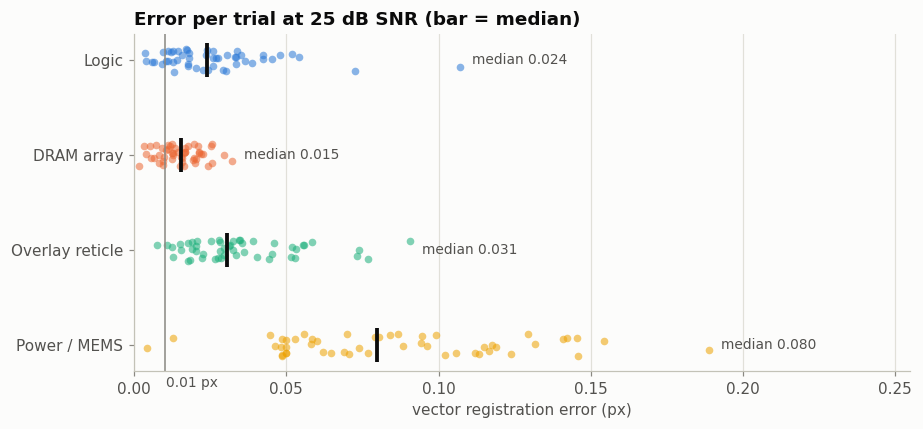

In [5]:
fig, ax = plt.subplots(figsize=(8.5, 4))
for i, (name, color) in enumerate(zip(refs, SERIES)):
    v = by_wafer.loc[by_wafer.wafer == name, "vector error (px)"].values
    ax.plot(v, np.full_like(v, i) + rng.uniform(-0.12, 0.12, v.size), "o", ms=5, color=color, alpha=0.55, mec="none")
    ax.plot([np.median(v)], [i], "|", ms=22, mew=2.5, color=INK)
    ax.text(v.max() + 0.004, i, f"median {np.median(v):.3f}", va="center", fontsize=9, color=INK2)
ax.axvline(0.01, color=MUTED, lw=1); ax.text(0.0105, 3.45, "0.01 px", fontsize=9, color=INK2)
ax.set_yticks(range(len(refs)), list(refs)); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set_xlabel("vector registration error (px)"); ax.set_xlim(0, by_wafer["vector error (px)"].max() * 1.35)
ax.set_title("Error per trial at 25 dB SNR (bar = median)")
plt.tight_layout(); fig.savefig(FIG / "accuracy_by_wafer_25db.png"); plt.show()

## 5 · Noise sensitivity: 15–40 dB SNR, 50 random shifts per point

In [6]:
snrs = [15, 20, 25, 30, 35, 40]
sweep = pd.DataFrame([{"wafer": n, "snr_db": s, "err": trial(img, s)} for n, img in refs.items() for s in snrs for _ in range(50)])
snr_table = sweep.pivot_table(index="snr_db", columns="wafer", values="err", aggfunc="mean")[list(refs)].round(4)
snr_table["all wafers"] = sweep.groupby("snr_db")["err"].mean().round(4)
snr_table.to_csv(RESULTS / "metrics/accuracy_vs_snr.csv")
snr_table

wafer,Logic,DRAM array,Overlay reticle,Power / MEMS,all wafers
snr_db,,,,,
15,0.0512,0.0333,0.0774,0.1911,0.0883
20,0.0375,0.0235,0.0452,0.1320,0.0595
25,0.0246,0.0160,0.0331,0.0784,0.0380
30,0.0172,0.0121,0.0225,0.0578,0.0274
35,0.0129,0.0087,0.0178,0.0404,0.0200
40,0.0099,0.0069,0.0148,0.0256,0.0143


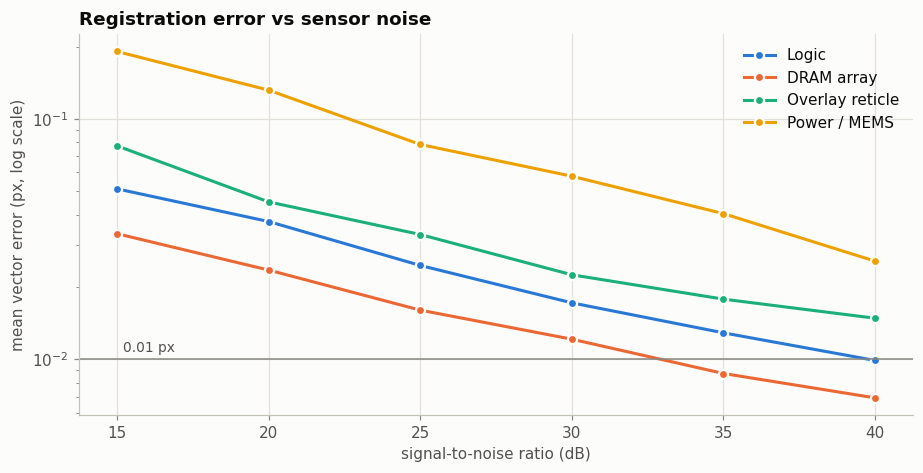

In [7]:
fig, ax = plt.subplots(figsize=(8.5, 4.4))
for name, color in zip(refs, SERIES):
    m = sweep[sweep.wafer == name].groupby("snr_db")["err"].mean()
    ax.plot(m.index, m.values, "-o", color=color, ms=6, mec="#fcfcfb", mew=1.5, label=name)
ax.axhline(0.01, color=MUTED, lw=1); ax.text(15.2, 0.0107, "0.01 px", fontsize=9, color=INK2)
ax.set_yscale("log"); ax.set_xlabel("signal-to-noise ratio (dB)"); ax.set_ylabel("mean vector error (px, log scale)")
ax.set_title("Registration error vs sensor noise"); ax.legend(loc="upper right")
plt.tight_layout(); fig.savefig(FIG / "accuracy_vs_snr.png"); plt.show()

## 6 · Speed

In [8]:
t = add_noise_snr(apply_subpixel_shift_fourier(ref, 2.3, -1.7), 30, rng)
register_subpixel_dft(ref, t, UPSAMPLE)                      # warm-up
times = []
for _ in range(50):
    t0 = time.perf_counter(); register_subpixel_dft(ref, t, UPSAMPLE); times.append((time.perf_counter() - t0) * 1000)
print(f"512x512 pair, upsample 100: median {np.median(times):.1f} ms, p95 {np.percentile(times, 95):.1f} ms (CPU, NumPy/SciPy)")

512x512 pair, upsample 100: median 21.7 ms, p95 79.1 ms (CPU, NumPy/SciPy)


## 7 · Reading the results and limitations

* **Pattern content dominates.** Fine, high-frequency patterns (DRAM array, logic grid) register far more precisely than the wide, low-frequency power/MEMS fingers, whose phase information concentrates in few frequencies.
* **The 0.01 px grid is a floor.** With κ = 100 the estimate is quantised to 0.01 px, so even noiseless errors sit around 0.003–0.007 px.
* **Best-case benchmark.** Targets are shifted with the same Fourier model the method assumes (circular, pure translation, identical illumination). Real images add rotation, scale, defocus differences and edge effects; windowing (e.g. Hann) before the FFT and a rotation/scale stage (log-polar) are the natural next steps, followed by tests on real optical images.